<a href="https://colab.research.google.com/github/Kerry-lab/SemProject_MLEngine/blob/main/Logistic_Regression_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Loading the dataset

In [ ]:
df = pd.read_csv('student_spending (1).csv')

In [ ]:
df.head() #to check the first five rows

,Unnamed: 0,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method
0,0,19,Non-binary,Freshman,Psychology,958,270,5939,709,296,123,188,41,78,134,127,72,Credit/Debit Card
1,1,24,Female,Junior,Economics,1006,875,4908,557,365,85,252,74,92,226,129,68,Credit/Debit Card
2,2,24,Non-binary,Junior,Economics,734,928,3051,666,220,137,99,130,23,239,112,133,Cash
3,3,23,Female,Senior,Computer Science,617,265,4935,652,289,114,223,99,30,163,105,55,Mobile Payment App
4,4,20,Female,Senior,Computer Science,810,522,3887,825,372,168,194,48,71,88,71,104,Credit/Debit Card


In [ ]:
#checking for missing values
#There are no missing values in the dataset
df.isnull().sum()

,0
Unnamed: 0,0
age,0
gender,0
year_in_school,0
major,0
monthly_income,0
financial_aid,0
tuition,0
housing,0
food,0


In [ ]:
#checking for duplicates
#There are no duplicates in the dataset
df.duplicated().sum()

np.int64(0)

In [ ]:
#checking the datatypes
df.dtypes

,0
Unnamed: 0,int64
age,int64
gender,object
year_in_school,object
major,object
monthly_income,int64
financial_aid,int64
tuition,int64
housing,int64
food,int64


In [ ]:
#Checking for outliers using the IQR method
#Identify numerical columns (excluding the index column 'Unnamed: 0')
#There are no outliers in this dataset
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop('Unnamed: 0', errors='ignore')

outliers_summary = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count outliers
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outliers_summary[col] = len(outliers)

# Display the count of outliers per column
outliers_df = pd.DataFrame(list(outliers_summary.items()), columns=['Column', 'Outliers Count'])
display(outliers_df)

,Column,Outliers Count
0,age,0
1,monthly_income,0
2,financial_aid,0
3,tuition,0
4,housing,0
5,food,0
6,transportation,0
7,books_supplies,0
8,entertainment,0
9,personal_care,0


In [ ]:
# Clean string categories (strip spaces, consistent casing)
cat_cols = ["gender", "year_in_school", "major", "preferred_payment_method"]
for col in cat_cols:
  if col in df.columns:
    df[col] = df[col].astype(str).str.strip()

In [ ]:
#  Define monthly expense columns vs. tuition (check if tuition is per-semester)
monthly_expense_cols = [
    "housing",
    "food",
    "transportation",
    "books_supplies",
    "entertainment",
    "personal_care",
    "technology",
    "health_wellness",
    "miscellaneous",
]

In [ ]:
# Verify numeric types & ensure no negative amounts
num_cols = ["age", "monthly_income", "financial_aid", "tuition"] + [
    c for c in monthly_expense_cols if c in df.columns
]
for col in num_cols:
  if col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].clip(lower=0)

In [ ]:
# 4. Engineer Kula Kesho Save Leo features
present_monthly_cols = [c for c in monthly_expense_cols if c in df.columns]
df["monthly_non_tuition_spend"] = df[present_monthly_cols].sum(axis=1)
df["total_available_funds"] = df["monthly_income"] + df["financial_aid"]
df["net_monthly_cashflow"] = (
    df["total_available_funds"] - df["monthly_non_tuition_spend"]
)
df["spend_to_income_ratio"] = np.where(
    df["monthly_income"] > 0,
    df["monthly_non_tuition_spend"] / df["monthly_income"],
    0.0,
)

In [ ]:
# Dominant spending category (target for category classification)
df["Top_Expense_Category"] = df[present_monthly_cols].idxmax(axis=1)

In [ ]:
# Spending tier (target for tier classification)
df["Spending_Tier"] = pd.qcut(
    df["monthly_non_tuition_spend"],
    q=3,
    labels=["Save Leo (Low)", "Balanced (Mid)", "Kula Heavy (High)"],
)

In [ ]:
# Synthetic transaction note column in case you want TF-IDF text classification
# (matches your earlier Notes_Clean -> TfidfVectorizer workflow when no raw text column exists)
df["Notes_Clean"] = (
    df["year_in_school"].fillna("")
    + " "
    + df["major"].fillna("")
    + " spending on "
    + df["Top_Expense_Category"].str.replace("_", " ", regex=False)
    + " via "
    + df["preferred_payment_method"].fillna("")
)

print("Cleaned shape:", df.shape)
df[[
    "monthly_income",
    "financial_aid",
    "monthly_non_tuition_spend",
    "net_monthly_cashflow",
    "Top_Expense_Category",
    "Spending_Tier",
]].head()

Cleaned shape: (1000, 25)


,monthly_income,financial_aid,monthly_non_tuition_spend,net_monthly_cashflow,Top_Expense_Category,Spending_Tier
0,958,270,1768,-540,housing,Balanced (Mid)
1,1006,875,1848,33,housing,Balanced (Mid)
2,734,928,1759,-97,housing,Balanced (Mid)
3,617,265,1730,-848,housing,Balanced (Mid)
4,810,522,1941,-609,housing,Kula Heavy (High)


In [ ]:
df = df.drop(columns="Unnamed: 0")

exp_cols = ["housing","food","transportation","books_supplies",
            "entertainment","personal_care","technology",
            "health_wellness","miscellaneous"]

df["monthly_spend"] = df[exp_cols].sum(axis=1)
df["total_funds"] = df["monthly_income"] + df["financial_aid"]
df["net_cashflow"] = df["total_funds"] - df["monthly_spend"]
df["spend_to_funds_ratio"] = df["monthly_spend"] / df["total_funds"]
df["overspends"] = (df["net_cashflow"] < 0).astype(int)

EDA

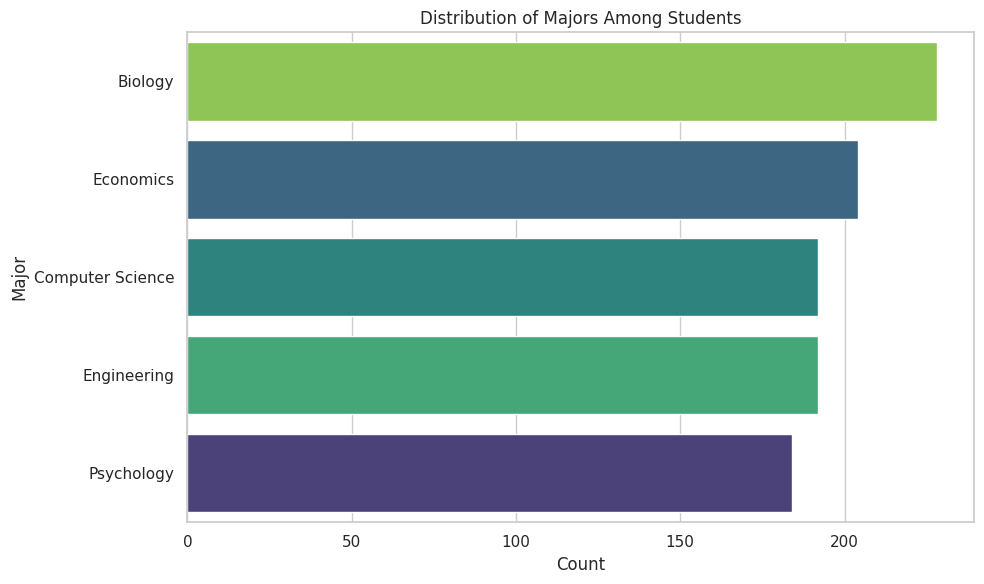

In [ ]:
#Data Visualization
# a)Bar Chart- To show which majors are common
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    y='major',
    order=df['major'].value_counts().index,
    palette='viridis',
    hue='major',
    legend=False
)

plt.title('Distribution of Majors Among Students')
plt.xlabel('Count')
plt.ylabel('Major')
plt.tight_layout()
plt.show()

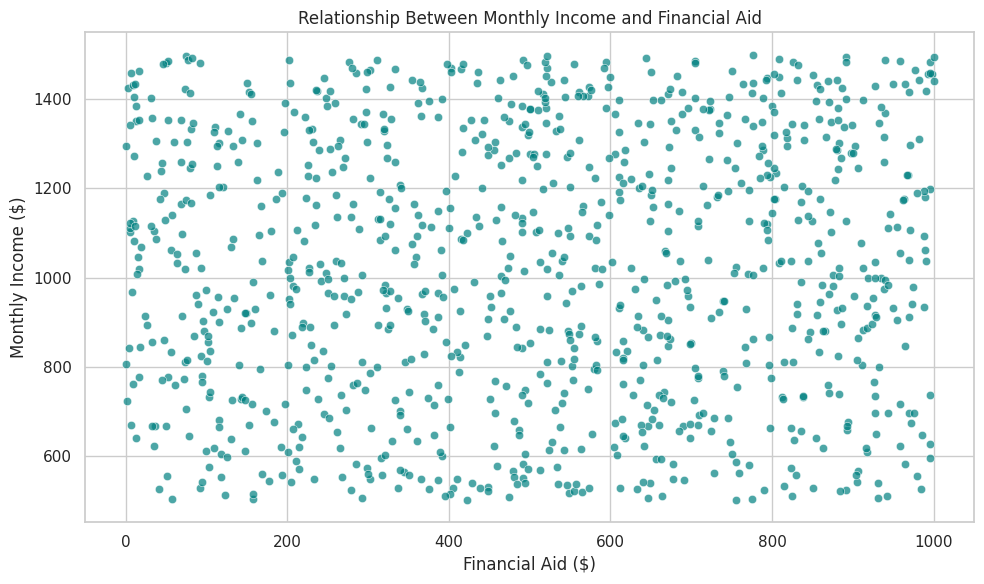

In [ ]:
# b) Scatter Plot - Monthly Income vs. Financial Aid
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='financial_aid', y='monthly_income', alpha=0.7, color='teal')

plt.title('Relationship Between Monthly Income and Financial Aid')
plt.xlabel('Financial Aid ($)')
plt.ylabel('Monthly Income ($)')
plt.tight_layout()
plt.show()

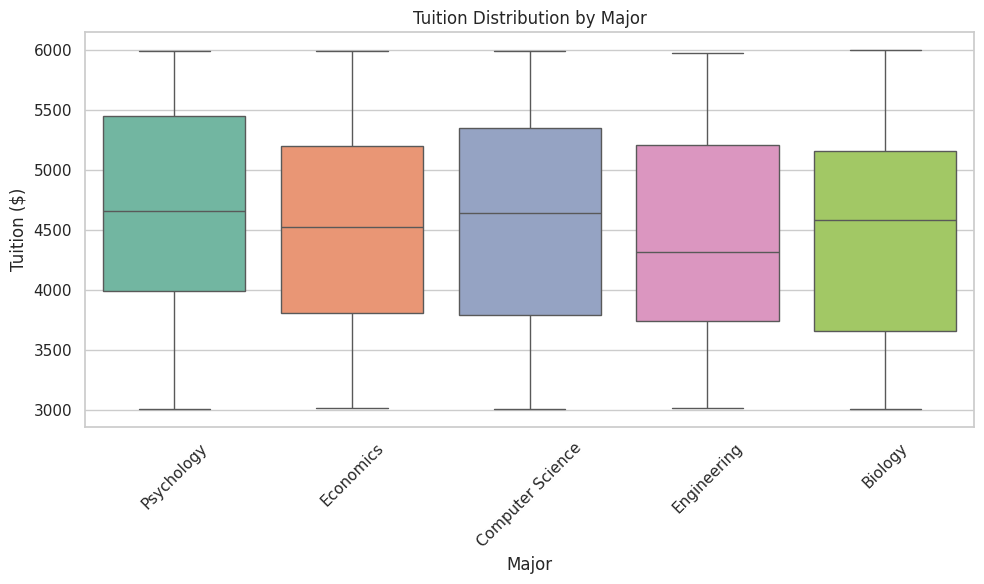

In [ ]:
# c) Boxplot - Tuition Distribution by Major
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='major', y='tuition', palette='Set2', hue='major', legend=False)

plt.title('Tuition Distribution by Major')
plt.xlabel('Major')
plt.ylabel('Tuition ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

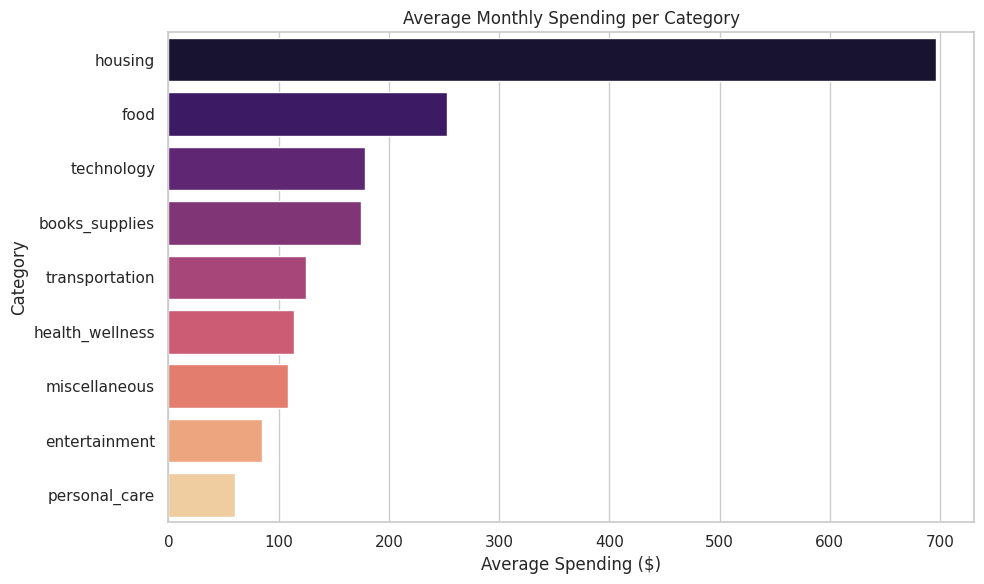

In [ ]:
# d) Bar Chart - Average Spending per Category
spending_cols = ['housing', 'food', 'transportation', 'books_supplies', 'entertainment', 'personal_care', 'technology', 'health_wellness', 'miscellaneous']
avg_spending = df[spending_cols].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=avg_spending.values, y=avg_spending.index, palette='magma', hue=avg_spending.index, legend=False)

plt.title('Average Monthly Spending per Category')
plt.xlabel('Average Spending ($)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

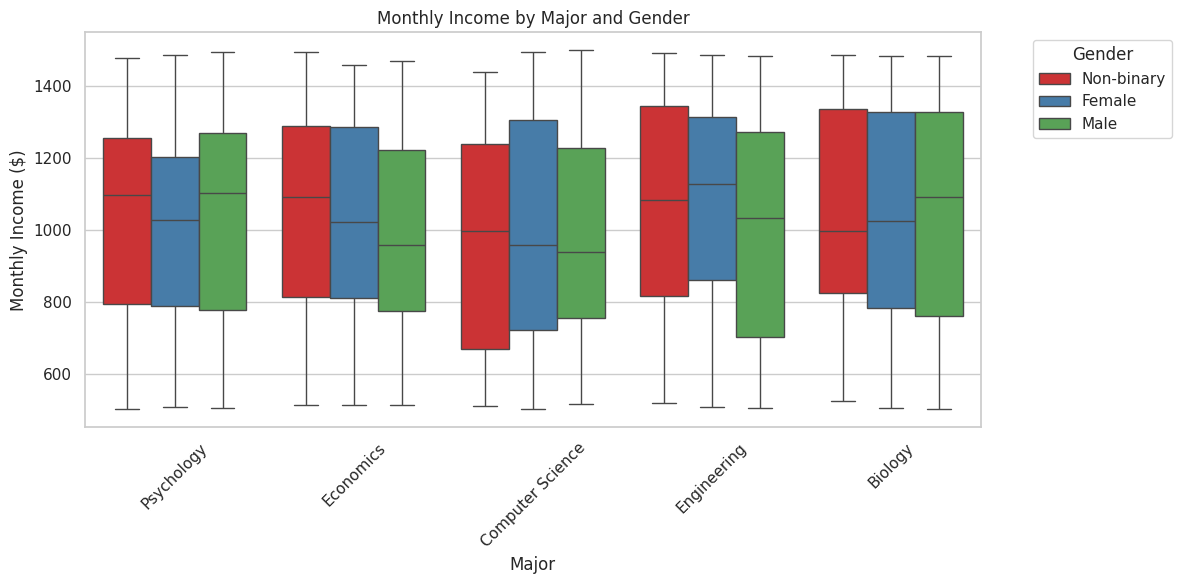

In [ ]:
# e) Boxplot - Monthly Income by Major and Gender
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='major', y='monthly_income', hue='gender', palette='Set1')

plt.title('Monthly Income by Major and Gender')
plt.xlabel('Major')
plt.ylabel('Monthly Income ($)')
plt.xticks(rotation=45)
plt.legend(title='Gender', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Classification Model, Test Results and Confusion Matrix
"We used a Logistic Regression model to predict the student's top spending category based on their personal and spending information.

We split the data into training and testing sets to train the model and check how well it performs.

We also prepared the data by scaling numerical values and converting text categories into numbers.

Finally, we used the test results and confusion matrix to see how accurately the model makes predictions."

Target class counts:
 overspends
1    705
0    295
Name: count, dtype: int64

Training set size: 800 samples
Testing set size: 200 samples

Accuracy: 0.8850

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.85      0.75      0.79        59
           1       0.90      0.94      0.92       141

    accuracy                           0.89       200
   macro avg       0.87      0.84      0.86       200
weighted avg       0.88      0.89      0.88       200



,Student Profile (Input),Actual Overspend Status,Model Prediction (Guess),Correct?
0,Junior | Biology | Inc=1176,0,0,True
1,Senior | Computer Science | Inc=595,1,1,True
2,Sophomore | Psychology | Inc=1333,1,1,True
3,Junior | Engineering | Inc=1022,1,1,True
4,Junior | Psychology | Inc=796,1,1,True
5,Freshman | Engineering | Inc=528,1,1,True
6,Freshman | Economics | Inc=758,1,1,True
7,Senior | Engineering | Inc=1483,0,0,True
8,Junior | Economics | Inc=916,0,0,True
9,Freshman | Computer Science | Inc=1454,0,0,True


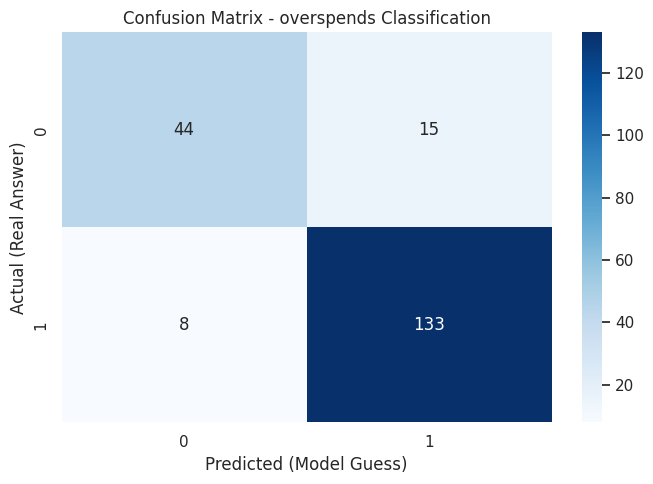

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Define Features (X) and Target (y)
# Use 'overspends' (or 'Spending_Tier') since 'Top_Expense_Category' only had 1 class ('housing')
target_col = "overspends"  # or "Spending_Tier"

feature_cols_num = [
    c for c in ["age", "monthly_income", "financial_aid", "tuition"] if c in df.columns
]
feature_cols_cat = [
    c
    for c in ["gender", "year_in_school", "major", "preferred_payment_method"]
    if c in df.columns
]

X = df[feature_cols_num + feature_cols_cat]
y = df[target_col]

print("Target class counts:\n", y.value_counts())

# 2. Split 80% train, 20% test (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nTraining set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

# 3. Preprocess & create Logistic Regression model pipeline
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), feature_cols_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), feature_cols_cat),
])

clf_model = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])

# 4. Train & Test
clf_model.fit(X_train, y_train)
y_pred = clf_model.predict(X_test)

print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

# 5. Inspect model predictions side-by-side
model_budget_predictions = pd.DataFrame({
    "Student Profile (Input)": (
        X_test["year_in_school"].astype(str)
        + " | "
        + X_test["major"].astype(str)
        + " | Inc="
        + X_test["monthly_income"].astype(str)
    ).values,
    "Actual Overspend Status": y_test.values,
    "Model Prediction (Guess)": y_pred,
})

# Check if the model's budget prediction was correct
model_budget_predictions["Correct?"] = (
    model_budget_predictions["Actual Overspend Status"]
    == model_budget_predictions["Model Prediction (Guess)"]
)

# Display the first 10 predictions
display(model_budget_predictions.head(10))

# 6. Confusion Matrix
labels_order = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels_order)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels_order,
    yticklabels=labels_order,
)
plt.title(f"Confusion Matrix - {target_col} Classification")
plt.xlabel("Predicted (Model Guess)")
plt.ylabel("Actual (Real Answer)")
plt.tight_layout()
plt.show()

Regression Model ("The Regression Thing")
This trains a regression model to predict the continuous numeric value of monthly_non_tuition_spend (how much a student spends per month outside tuition), compares Ridge Regression vs. Random Forest Regressor, and plots actual vs. predicted spending.

=== Ridge Regression ===
MAE : 192.79
RMSE: 240.75
R^2 : -0.0184

=== Random Forest Regressor ===
MAE : 196.91
RMSE: 246.94
R^2 : -0.0714



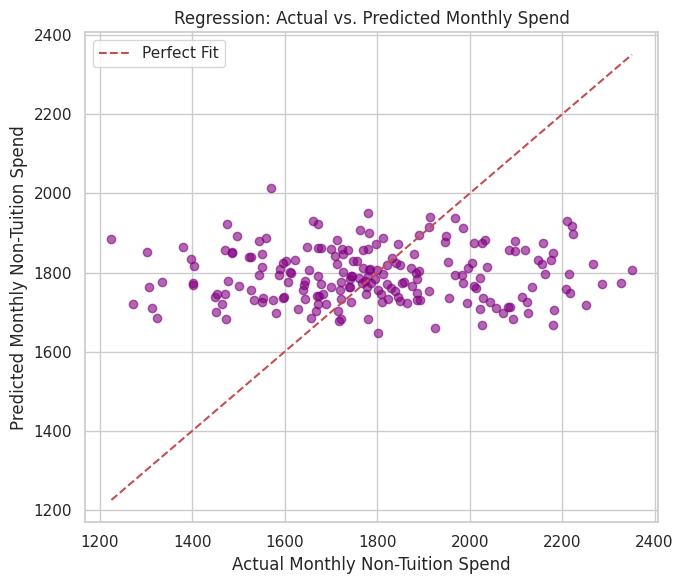

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Define numeric predictors (exclude target & direct sum components) and categorical predictors
reg_num_cols = [
    c for c in ["age", "monthly_income", "financial_aid", "tuition"] if c in df.columns
]
reg_cat_cols = [
    c
    for c in ["gender", "year_in_school", "major", "preferred_payment_method"]
    if c in df.columns
]

X_reg = df[reg_num_cols + reg_cat_cols]
y_reg = df["monthly_non_tuition_spend"]

# 2. Split 80% train, 20% test
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

reg_preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), reg_num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), reg_cat_cols),
])

models = {
    "Ridge Regression": Ridge(alpha=1.0, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200, random_state=42
    ),
}

# 3. Train, test & evaluate each regressor
for name, estimator in models.items():
  pipe = Pipeline(steps=[("prep", reg_preprocessor), ("reg", estimator)])
  pipe.fit(X_train_r, y_train_r)
  preds = pipe.predict(X_test_r)

  mae = mean_absolute_error(y_test_r, preds)
  rmse = np.sqrt(mean_squared_error(y_test_r, preds))
  r2 = r2_score(y_test_r, preds)
  print(f"=== {name} ===")
  print(f"MAE : {mae:.2f}")
  print(f"RMSE: {rmse:.2f}")
  print(f"R^2 : {r2:.4f}\n")

# 4. Plot Actual vs. Predicted for Random Forest Regressor
best_pipe = Pipeline(steps=[
    ("prep", reg_preprocessor),
    ("reg", RandomForestRegressor(n_estimators=200, random_state=42)),
])
best_pipe.fit(X_train_r, y_train_r)
y_pred_r = best_pipe.predict(X_test_r)

plt.figure(figsize=(7, 6))
plt.scatter(y_test_r, y_pred_r, alpha=0.6, color="purple")
min_val = min(y_test_r.min(), y_pred_r.min())
max_val = max(y_test_r.max(), y_pred_r.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--", label="Perfect Fit")
plt.title("Regression: Actual vs. Predicted Monthly Spend")
plt.xlabel("Actual Monthly Non-Tuition Spend")
plt.ylabel("Predicted Monthly Non-Tuition Spend")
plt.legend()
plt.tight_layout()
plt.show()

---
## Part 2: Second Model Workflow

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

using the hostel life expense tracker in the notebook

In [ ]:
df = pd.read_csv("hostel_life_expense_tracker.csv")


Handling missing values in the dataset

In [ ]:
df.isnull().sum()

,0
Date,0
Expense_Type,0
Amount,0
Payment_Mode,0
Notes,0


In [ ]:
df.duplicated().sum()

np.int64(1)

dropping the 1 duplicate shown

In [ ]:
df= df.drop_duplicates()

Confirming it is dropped

In [ ]:
df.duplicated().sum()

np.int64(0)

Converting Text Labels to Numbers- because Machine learning models cannot process raw text strings directly

In [ ]:
#changing the target column using labelencoder
df = df.copy()

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Expense_Type_Encoded'] = le.fit_transform(df['Expense_Type'])

In [ ]:
#changing the column on payment mode using the pd.get_dummies
df = pd.get_dummies(df, columns=['Payment_Mode'], drop_first=True)

In [ ]:
#trying to confirm it has worked
df.head()

,Date,Expense_Type,Amount,Notes,Expense_Type_Encoded,Payment_Mode_UPI
0,2025-01-01,Snacks,40,Bought biscuits,4,False
1,2025-01-01,Travel,20,Auto to bus stand,6,False
2,2025-01-01,Food,110,Evening dinner outside,0,True
3,2025-01-02,Stationary,35,Pen and notebook,5,True
4,2025-01-02,Snacks,30,Tea and samosa,4,True


Normalizing texts so that the model treats words with different caps or punctuation marks as one

In [ ]:
import re

# 1. Text Normalization on Notes
df['Notes_Clean'] = df['Notes'].astype(str).str.lower()
df['Notes_Clean'] = df['Notes_Clean'].apply(lambda x: re.sub(r'[^a-zA-Z0-9\s]', '', x).strip())

In [ ]:
df.head()


,Date,Expense_Type,Amount,Notes,Expense_Type_Encoded,Payment_Mode_UPI,Notes_Clean
0,2025-01-01,Snacks,40,Bought biscuits,4,False,bought biscuits
1,2025-01-01,Travel,20,Auto to bus stand,6,False,auto to bus stand
2,2025-01-01,Food,110,Evening dinner outside,0,True,evening dinner outside
3,2025-01-02,Stationary,35,Pen and notebook,5,True,pen and notebook
4,2025-01-02,Snacks,30,Tea and samosa,4,True,tea and samosa


Date formatting -converting raw text date to pandas official date time format

In [ ]:
# 2. Date Formatting & Temporal Feature Engineering
df['Date'] = pd.to_datetime(df['Date'])
df['Day_of_Week'] = df['Date'].dt.dayofweek
df['Month'] = df['Date'].dt.month

In [ ]:
df.head()

,Date,Expense_Type,Amount,Notes,Expense_Type_Encoded,Payment_Mode_UPI,Notes_Clean,Day_of_Week,Month
0,2025-01-01,Snacks,40,Bought biscuits,4,False,bought biscuits,2,1
1,2025-01-01,Travel,20,Auto to bus stand,6,False,auto to bus stand,2,1
2,2025-01-01,Food,110,Evening dinner outside,0,True,evening dinner outside,2,1
3,2025-01-02,Stationary,35,Pen and notebook,5,True,pen and notebook,3,1
4,2025-01-02,Snacks,30,Tea and samosa,4,True,tea and samosa,3,1


Making sure amount is strictly formatted as interger and float

In [ ]:
# 3. Numeric Formatting for Amount
df['Amount'] = pd.to_numeric(df['Amount'], errors='coerce')

df['Amount'].dtype

dtype('int64')

Part 2:Doing the EDA

In [ ]:
#Adding clean backgrounds on charts for visibility
sns.set_theme(style="whitegrid")
#Creating a canvas size 14 by 10
plt.figure(figsize=(14, 10))

<Figure size 1400x1000 with 0 Axes>

<Figure size 1400x1000 with 0 Axes>

1: Trying to get number of transaction occurences for each category

Text(0.5, 0, 'Count')

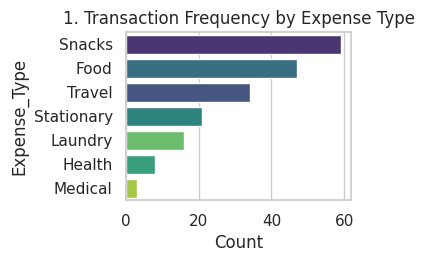

In [ ]:
#Dividing the canvas to 4 sections and putting this part to section 1(i.e. 2 rows and 2 columns)
plt.subplot(2, 2, 1)
#Counting how many transaction rows exist for each category i.e. Food, Snacks
sns.countplot(data=df, y='Expense_Type', order=df['Expense_Type'].value_counts().index,hue='Expense_Type', palette='viridis',legend=False)
plt.title('1. Transaction Frequency by Expense Type')
plt.xlabel('Count')

2:How much is spent on each transation

Text(0.5, 0, 'Amount')

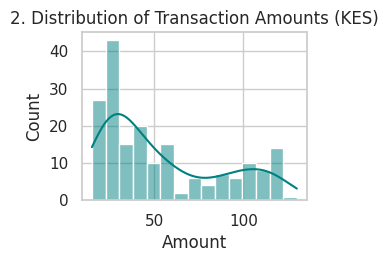

In [ ]:
#places this om position 2
plt.subplot(2, 2, 2)
#Groups transaction amounts into numerical buckets to show how much money is spent per transaction.
#KDE draws a line that traces over the bars to show you where spending was concentrated
sns.histplot(df['Amount'], kde=True, bins=15, color='teal')
plt.title('2. Distribution of Transaction Amounts (KES)')
plt.xlabel('Amount')

3:Getting the pattern in the week where most people spend their money like which day they mostly do their spendings



Text(0, 0.5, 'Total Amount')

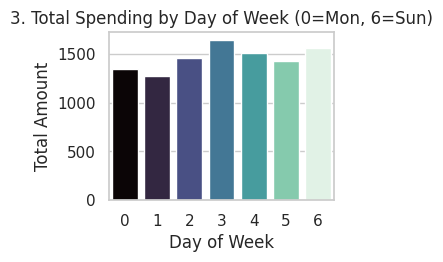

In [ ]:
#Position 3
plt.subplot(2, 2, 3)
#Sums up total spendings for each day to highlight whether spending is on weekday or weekends
sns.barplot(data=df, x='Day_of_Week', y='Amount', estimator='sum', errorbar=None, hue='Day_of_Week', palette='mako', legend=False)
plt.title('3. Total Spending by Day of Week (0=Mon, 6=Sun)')
plt.xlabel('Day of Week')
plt.ylabel('Total Amount')

4:Trying to see how people are paying cash or mpesa

Text(0, 0.5, 'Count')

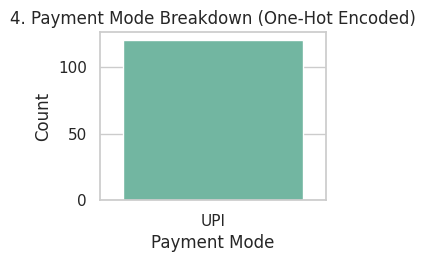

In [ ]:
# Position 4
plt.subplot(2, 2, 4)

# Finding all dummy columns created by pd.get_dummies for Payment_Mode
payment_cols = [col for col in df.columns if col.startswith('Payment_Mode_')]

# Adding up the 1s for each payment dummy column
payment_counts = df[payment_cols].sum().reset_index()
payment_counts.columns = ['Payment_Mode', 'Count']

#Cleanimg up the label names on the chart (removes 'Payment_Mode_' prefix so it looks neat)
payment_counts['Payment_Mode'] = payment_counts['Payment_Mode'].str.replace('Payment_Mode_', '')

# 4. Draw the bar chart using Seaborn
sns.barplot(data=payment_counts, x='Payment_Mode', y='Count', hue='Payment_Mode', palette='Set2', legend=False)
plt.title('4. Payment Mode Breakdown (One-Hot Encoded)')
plt.xlabel('Payment Mode')
plt.ylabel('Count')

Text(0, 0.5, 'Count')

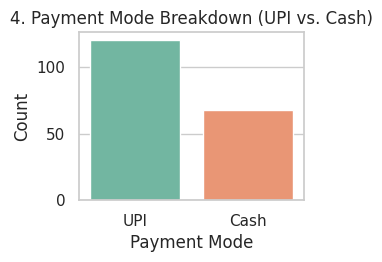

In [ ]:
# Position 4
plt.subplot(2, 2, 4)

# 1. Count UPI (where value is 1) and Cash (where value is 0)
upi_count = df['Payment_Mode_UPI'].sum()
cash_count = len(df) - upi_count

# 2. Create a small DataFrame with both counts
payment_data = pd.DataFrame({
    'Payment_Mode': ['UPI', 'Cash'],
    'Count': [upi_count, cash_count]
})

# 3. Draw the bar chart showing both payment methods
sns.barplot(data=payment_data, x='Payment_Mode', y='Count', hue='Payment_Mode', palette='Set2', legend=False)
plt.title('4. Payment Mode Breakdown (UPI vs. Cash)')
plt.xlabel('Payment Mode')
plt.ylabel('Count')

Part 3:TRAINING THE MODEL

1:converting the unstructured text notes e.g."bought smokies and soda"into mathematical numerical vectors using TF-IDF

LabelEncoder only works for clean, single-word categories like "Food". It cannot understand full sentences or descriptions with multiple unique words

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Define Features (X-The questions) and Target (y-answers)
X_text = df['Notes_Clean']
y = df['Expense_Type_Encoded']

# 2. Converting the text notes to numbers(vectors) using TF-IDF
tfidf = TfidfVectorizer(max_features=500)
X_tfidf = tfidf.fit_transform(X_text)

# Spilliting the training and testing data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 150 samples
Testing set size: 38 samples


 A model is just a python variable inside colab used to store rules ( a smart rulebook)
 Before .fit() we have an empty rulebook

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Create the blank model creates the variable, but it has no rules yet. If you ask it to predict, it doesn't know anything.(the empty "brain")

model = LogisticRegression(random_state=42)

#Train the model (This is where it learns the patterns from X_train and y_train)
#it reads the 150 questions and answers and saves the pattern rules inside model
model.fit(X_train, y_train)

#Test the model (Ask it to predict answers for the 38 unseen test questions and stores in y_pred)
y_pred = model.predict(X_test)

#Compares the model's guesses (y_pred) against the real answers (y_test) and calculates your final test score
#Print the score report to see how well it performed
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

--- Classification Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         9
           1       0.00      0.00      0.00         2
           2       1.00      0.67      0.80         3
           3       0.00      0.00      0.00         1
           4       0.71      1.00      0.83        12
           5       1.00      0.75      0.86         4
           6       1.00      1.00      1.00         7

    accuracy                           0.87        38
   macro avg       0.67      0.63      0.64        38
weighted avg       0.83      0.87      0.84        38



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


  Trying to see a table of the 1st 10 items that was fed to the model and how it did with the prediction

In [ ]:
# Create the results view directly from X_text
exam_results = pd.DataFrame({
    'Transaction Note (Question)': X_text.loc[y_test.index].values,
    'Actual Category (Real Answer)': y_test.values,
    'Model Prediction (Guess)': y_pred
})

# Add a column checking if the guess was correct
exam_results['Correct?'] = exam_results['Actual Category (Real Answer)'] == exam_results['Model Prediction (Guess)']

exam_results.head(10)

,Transaction Note (Question),Actual Category (Real Answer),Model Prediction (Guess),Correct?
0,puffs,4,4,True
1,share auto,6,6,True
2,bus fare,6,6,True
3,puffs,4,4,True
4,cold tablets,1,4,False
5,washing,2,4,False
6,milkshake,4,4,True
7,meals outside,0,0,True
8,cold coffee,4,4,True
9,meals,0,0,True


Constructing a confusion matrix grid
A Confusion Matrix is simply a visual grid that shows you where the model got confused

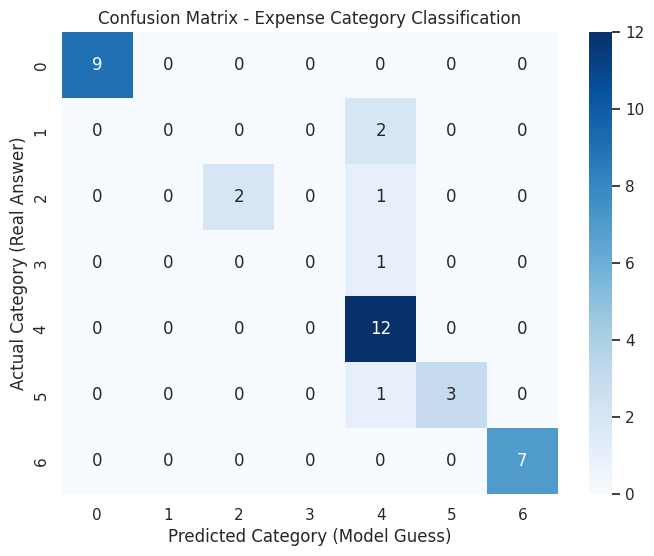

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Generate confusion matrix values
cm = confusion_matrix(y_test, y_pred)

# 2. Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Expense Category Classification')
plt.xlabel('Predicted Category (Model Guess)')
plt.ylabel('Actual Category (Real Answer)')
plt.show()